In [10]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import re
from itertools import combinations
from scipy.stats import ttest_ind

In [ ]:
# HELPER FUNCTIONS
# for time 
def time_to_seconds(t):
    if pd.isna(t):
        return None
    # make sure it's a string
    t = str(t).strip()
    # parse HH:MM:SS (or MM:SS) to seconds
    return pd.to_timedelta(t).total_seconds()

# blank correction
def blank_correction(df: pd.DataFrame, blank_wells: list[str]) -> pd.DataFrame:
    blank_series = df[blank_wells].mean(axis=1)
    return df.drop(columns=blank_wells).sub(blank_series, axis=0)

# compute volumetric activity
def compute_activity_U_mL(
    df: pd.DataFrame,
    volume,
    *,
    epsilon: float = 6.22,
    r_mm: float = 6.9 / 2,
    V_uL: float = 200,
    Ve_uL: float = 10,
    min_points: int = 2,
) -> pd.Series:
    """
    volume:
        - float → single volume for all samples
        - dict  → {volume_value: (sample_names, ...)}
    """

    x = df.index.to_numpy(float)

    # path length (cm)
    l_cm = (V_uL / (math.pi * r_mm**2)) / 10

    # constant part (everything except slope and volume)
    k_base = (V_uL * 60) / (epsilon * l_cm * Ve_uL)

    # --- resolve per-column volume ---
    if isinstance(volume, dict):
        volume_map = {}
        for vol, names in volume.items():
            for name in names:
                volume_map[name] = vol
    else:
        volume_map = None  # scalar case

    out = {}

    for col in df.columns:
        y = df[col].to_numpy(float)
        m = np.isfinite(x) & np.isfinite(y)

        if m.sum() < min_points:
            out[col] = np.nan
            continue

        slope = np.polyfit(x[m], y[m], 1)[0]

                # pick correct volume
        vol = volume_map[col] if volume_map is not None else volume

        out[col] = abs(slope) * (k_base / vol)

    return pd.Series(out, name="activity_U_mL")

# function to build useful OD df
def expand_OD_df(df_A, df_B, repeat=3, col2_name="OD"):

    # Keep BOTH well and activity
    col1_df = df_A.reset_index()
    col1_df.columns = ["Well", "Activity"]

    # OD part (skip first row, first 3 cols)
    flat = df_B.iloc[1:, :3].to_numpy().ravel(order="C")
    col2 = np.repeat(flat, repeat)

    if len(col1_df) != len(col2):
        raise ValueError("Length mismatch")

    col1_df[col2_name] = col2

    return col1_df

# normalize activity for OD
def normalize_activity(activity_series, df_OD, od_column="OD", id_col="Well"):

    od_map = df_OD.set_index(id_col)[od_column]

    activity_norm = activity_series / od_map

    return activity_norm.rename("activity_norm")

# pooling
# each biological sample contributes equally to the mean
# the SD is computed across biological samples (not technical replicates)
# n = number of biological samples, not total replicates 
def pooled_over_groups(
    s: pd.Series,
    replicates: int = 3,
    groups_per_pool: int = 3
) -> pd.DataFrame:
    
    if len(s) % replicates != 0:
        raise ValueError("Length of series must be divisible by number of replicates")

    pooled = []
    n_groups = len(s) // replicates

    for g0 in range(0, n_groups, groups_per_pool):
        # Collect biological groups
        block = [
            s.iloc[i * replicates:(i + 1) * replicates]
            for i in range(g0, min(g0 + groups_per_pool, n_groups))
        ]

        # Compute one mean per biological sample
        group_means = np.array(
            [g.mean(skipna=True) for g in block],
            dtype=float
        )

        # Remove NaNs (in case entire group is NaN)
        group_means = group_means[~np.isnan(group_means)]

        # Compute pooled stats at biological level
        if len(group_means) == 0:
            pooled_mean = np.nan
            pooled_sd = np.nan
            pooled_n = 0
        else:
            pooled_mean = group_means.mean()
            pooled_n = len(group_means)
            pooled_sd = (
                group_means.std(ddof=1)
                if pooled_n >= 2 else np.nan
            )

        pooled.append({
            "pool": g0 // groups_per_pool + 1,
            "mean": pooled_mean,
            "std": pooled_sd,
            "n": pooled_n,
        })

    return pd.DataFrame(pooled)

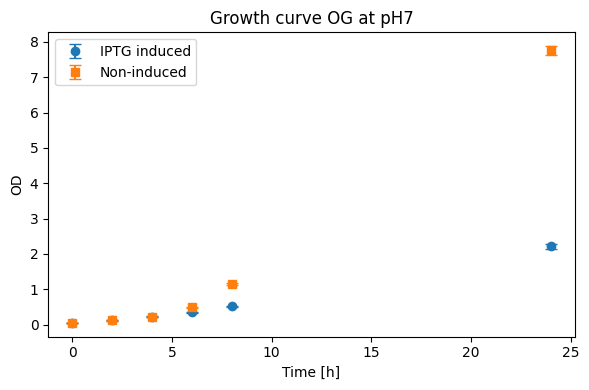

In [12]:
# plot OD
# load OD data
OD_OG_7 = pd.read_excel('OG7_OD_130226.xlsx')
OD_OG_7 = OD_OG_7.set_index('time [h]')
OD_OG_7 = OD_OG_7.apply(pd.to_numeric, errors="coerce")

group1 = OD_OG_7.iloc[:, 0:3]   # columns 1–3
group2 = OD_OG_7.iloc[:, 3:6]   # columns 4–6

OD_OG_7_summary = pd.DataFrame(index=OD_OG_7.index)

OD_OG_7_summary["mean_1_3"] = OD_OG_7.iloc[:, 0:3].mean(axis=1)
OD_OG_7_summary["std_1_3"]  = OD_OG_7.iloc[:, 0:3].std(axis=1)

OD_OG_7_summary["mean_4_6"] = OD_OG_7.iloc[:, 3:6].mean(axis=1)
OD_OG_7_summary["std_4_6"]  = OD_OG_7.iloc[:, 3:6].std(axis=1)

# PLOT
fig, ax = plt.subplots(figsize=(6, 4))

# Induced
ax.errorbar(OD_OG_7_summary.index, OD_OG_7_summary["mean_1_3"], yerr=OD_OG_7_summary["std_1_3"],
            fmt='o', capsize=4, label="IPTG induced")

# Non-induced
ax.errorbar(OD_OG_7_summary.index, OD_OG_7_summary["mean_4_6"], yerr=OD_OG_7_summary["std_4_6"],
            fmt='s', capsize=4, label="Non-induced")

ax.set_xlabel("Time [h]")
ax.set_ylabel("OD")
ax.legend()
ax.set_title('Growth curve OG at pH7')

plt.tight_layout()
plt.show()

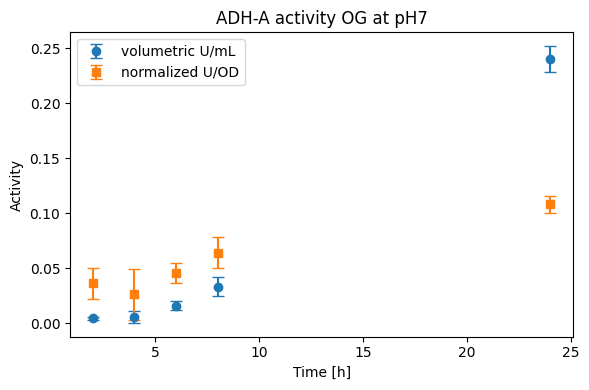

In [13]:
# ADH-A ACTIVITY

# calculate activity values
ADHA_OG_7 = pd.read_csv('OG7_ADHA_130226.CSV', delimiter=',', skiprows=5)

ADHA_OG_7 = ADHA_OG_7.iloc[1:-1, 1:]
ADHA_OG_7.iloc[:, 0] = ADHA_OG_7.iloc[:, 0].apply(time_to_seconds)
ADHA_OG_7 = ADHA_OG_7.set_index(ADHA_OG_7.columns[0]).rename_axis("Time [s]")
ADHA_OG_7 = ADHA_OG_7.apply(pd.to_numeric, errors="coerce")

# blank correction
ADHA_OG_7_corr = blank_correction(ADHA_OG_7, ['A01', 'A02'])

# make small overview plots
"""
ycols = ADHA_OG_7_corr.columns
groups = [ycols[i:i+3] for i in range(0, len(ycols), 3)]

for i in range(0, len(groups), 3):
    fig, axes = plt.subplots(1, 3, figsize=(8, 2), sharex=True, sharey=True)

    for ax, cols in zip(axes, groups[i:i+3]):
        ADHA_OG_7_corr[cols].plot(ax=ax, legend=False, alpha=0.8)

        ax.set_title(", ".join(cols), fontsize=9)
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Signal")
        ax.legend()

    plt.tight_layout()
    plt.show()
"""

# E06 needs to be removed!

# limit the time to 25x10s
ADHA_OG_7_corr = ADHA_OG_7_corr.loc[ADHA_OG_7_corr.index <= 250]

# volumetric activity
volumes = {1: ('B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09'),
           0.5: ('C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07', 'C08', 'C09'),
           0.33: ('D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09'),
           0.2: ('E01', 'E02', 'E03', 'E04', 'E05', 'E06', 'E07', 'E08', 'E09'),
           0.045: ('F01', 'F02', 'F03', 'F04', 'F05', 'F06', 'F07', 'F08', 'F09')}

act_OG_7_vol  = compute_activity_U_mL(ADHA_OG_7_corr, volume=volumes)

# drop unwanted samples
act_OG_7_vol['E06'] = np.nan

# normalize activity for OD
OD_OG_7_long = expand_OD_df(act_OG_7_vol, OD_OG_7, repeat=3)

act_OG_7_norm = normalize_activity(act_OG_7_vol, OD_OG_7_long, od_column="OD", id_col="Well")

# summarize
vol = pooled_over_groups(act_OG_7_vol).add_prefix("vol_")
norm = pooled_over_groups(act_OG_7_norm).add_prefix("norm_")

act_OG_7_summary = vol.merge(norm, left_on="vol_pool", right_on="norm_pool", how="outer")

# PLOT
x = [2, 4, 6, 8, 24]
fig, ax = plt.subplots(figsize=(6, 4))

# volumetric
ax.errorbar(x, act_OG_7_summary['vol_mean'], yerr=act_OG_7_summary['vol_std'],
            fmt='o', capsize=4, label='volumetric U/mL')

# normalized
ax.errorbar(x, act_OG_7_summary['norm_mean'], yerr=act_OG_7_summary['norm_std'],
            fmt='s', capsize=4, label='normalized U/OD')

ax.set_xlabel("Time [h]")
ax.set_ylabel("Activity")
ax.legend()
ax.set_title('ADH-A activity OG at pH7')

plt.tight_layout()
plt.show()

In [ ]:
# relative standard deviation activity
rel_std_OD = OD_OG_7_summary['std_1_3']/OD_OG_7_summary['mean_1_3']
#print(rel_std_OD)

rel_std_act_vol = act_OG_7_summary['vol_std']/act_OG_7_summary['vol_mean']
rel_std_act_norm = act_OG_7_summary['norm_std']/act_OG_7_summary['norm_mean']

print(rel_std_act_vol, rel_std_act_norm)

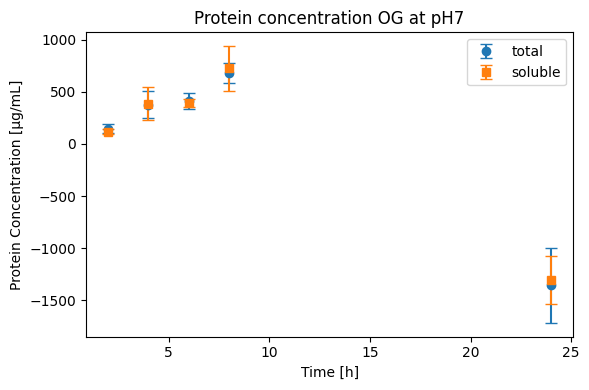

In [15]:
# BCA RESULTS
BCA_total_OG_7 = pd.read_csv('OG7_BCA1_130226.CSV', delimiter=',', skiprows=5)
BCA_soluble_OG_7 = pd.read_csv('OG7_BCA2_130226.CSV', delimiter=',', skiprows=5)

# delete line 1, 3
BCA_total_OG_7 = BCA_total_OG_7.drop(BCA_total_OG_7.index[[0, 2]])
BCA_soluble_OG_7 = BCA_soluble_OG_7.drop(BCA_soluble_OG_7.index[[0, 2]])

# delete calibration data but not blank
cols = list(BCA_total_OG_7.loc[:, 'A01':'A03'].columns) + \
       list(BCA_total_OG_7.loc[:, 'C04':].columns)

BCA_total_OG_7 = BCA_total_OG_7[cols]

# corece numeric
BCA_total_OG_7 = BCA_total_OG_7.apply(pd.to_numeric, errors="coerce")
BCA_soluble_OG_7 = BCA_soluble_OG_7.apply(pd.to_numeric, errors="coerce")

# blank correction
BCA_total_OG_7_corr = blank_correction(BCA_total_OG_7, ['A01', 'A02', 'A03'])
BCA_soluble_OG_7_corr = blank_correction(BCA_soluble_OG_7, ['A01', 'A02', 'A03'])

# protein concentration [µg/mL] calculation
# x = (y-d)/k
slope = 0.0010759827886111873
intercept = 0.14667156458848296

OG_7_protein_total_1 = (BCA_total_OG_7_corr-intercept)/slope
OG_7_protein_soluble_1 = (BCA_soluble_OG_7_corr-intercept)/slope

# delete one random NaN value
OG_7_protein_soluble_1 = OG_7_protein_soluble_1.drop(columns="Well", errors="ignore")

# correct for volume
volumes_BSA_total = {1: ('C04', 'C05', 'C06', 'C07', 'C08', 'C09', 'C10', 'C11', 'C12'),
                     0.5: ('D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09'),
                     0.33: ('D10', 'D11', 'D12', 'E01', 'E02', 'E03', 'E04', 'E05', 'E06'),
                     0.2: ('E07', 'E08', 'E09', 'E10', 'E11', 'E12', 'F01', 'F02', 'F03'),
                     0.045: ('F04', 'F05', 'F06', 'F07', 'F08', 'F09', 'F10', 'F11', 'F12')}

volumes_BSA_soluble = {1: ('A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12'),
                     0.5: ('B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09'),
                     0.33: ('B10', 'B11', 'B12', 'C01', 'C02', 'C03', 'C04', 'C05', 'C06'),
                     0.2: ('C07', 'C08', 'C09', 'C10', 'C11', 'C12', 'D01', 'D02', 'D03'),
                     0.045: ('D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12')}

# 1. Flip dict: well -> volume
well_to_vol_total = {
    well: vol
    for vol, wells in volumes_BSA_total.items()
    for well in wells
}

well_to_vol_soluble = {
    well: vol
    for vol, wells in volumes_BSA_soluble.items()
    for well in wells
}

# 2. Create aligned volume Series
vol_series_total = pd.Series(well_to_vol_total)
vol_series_soluble = pd.Series(well_to_vol_soluble)

# 3. Divide (pandas aligns by column names automatically)
OG_7_protein_total = OG_7_protein_total_1.divide(vol_series_total, axis=1)
OG_7_protein_soluble = OG_7_protein_soluble_1.divide(vol_series_soluble, axis=1)

# summarize
total = pooled_over_groups(OG_7_protein_total.squeeze()).add_prefix("total_")
soluble = pooled_over_groups(OG_7_protein_soluble.squeeze()).add_prefix("soluble_")

OG_7_protein_summary = total.merge(soluble, left_on="total_pool", right_on="soluble_pool", how="outer")

# PLOT
x = [2, 4, 6, 8, 24]
fig, ax = plt.subplots(figsize=(6, 4))

# total
ax.errorbar(x, OG_7_protein_summary['total_mean'], yerr=OG_7_protein_summary['total_std'],
            fmt='o', capsize=4, label='total')

# soluble
ax.errorbar(x, OG_7_protein_summary['soluble_mean'], yerr=OG_7_protein_summary['soluble_std'],
            fmt='s', capsize=4, label='soluble')

ax.set_xlabel("Time [h]")
ax.set_ylabel("Protein Concentration [µg/mL]")
ax.legend()
ax.set_title('Protein concentration OG at pH7')

plt.tight_layout()
plt.show()

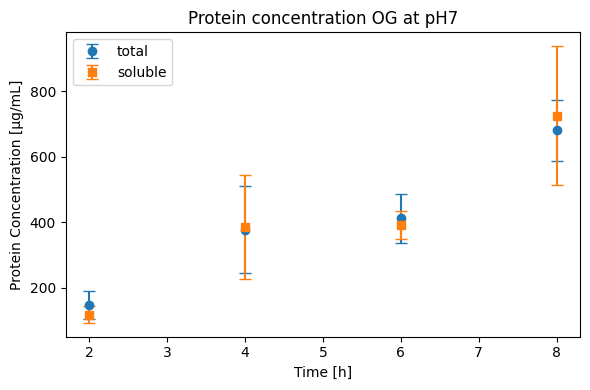

In [ ]:
# PLOT - without 24h values
x_plot = x[:-1]

fig, ax = plt.subplots(figsize=(6, 4))

# total
ax.errorbar(
    x_plot,
    OG_7_protein_summary['total_mean'][:-1],
    yerr=OG_7_protein_summary['total_std'][:-1],
    fmt='o', capsize=4, label='total'
)

# soluble
ax.errorbar(
    x_plot,
    OG_7_protein_summary['soluble_mean'][:-1],
    yerr=OG_7_protein_summary['soluble_std'][:-1],
    fmt='s', capsize=4, label='soluble'
)

ax.set_xlabel("Time [h]")
ax.set_ylabel("Protein Concentration [µg/mL]")
ax.legend()
ax.set_title('Protein concentration OG at pH7')

plt.tight_layout()
plt.show()

In [ ]:
# EXPORT results
OD_OG_7_summary.to_parquet('OD_OG_7_summary.parquet')
act_OG_7_summary.to_parquet('act_OG_7_summary.parquet')
OG_7_protein_summary.to_parquet('OG_7_protein_summary.parquet')